# PetroStream: Production & Maintenance Analysis

An operational analysis of synthetic oil-and-gas field data, focused on annual and monthly production, well-level changes, downtime, operating expenditure, and maintenance activity.

**Comparison period:** 2021–2022 for field, well, monthly, and maintenance comparisons; annual KPIs cover all available years.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mysql.connector
import os

## Data Access & Connection

The notebook reads the project’s local SQLite database, which is built from the CSV files in `data/`.

In [2]:
def db_connection():
    connect = mysql.connector.connect(
        host=os.getenv("DB_HOST", "localhost"),
        port=int(os.getenv("DB_PORT", "3307")),
        password=os.getenv("DB_PASSWORD", ""),
        user=os.getenv("DB_USER", "root"),
        database=os.getenv("DB_NAME", "petro_stream"))
    cursor = connect.cursor(dictionary=True)
    return connect, cursor

In [3]:
def sql_to_df(sql):
    connect, cursor = db_connection()
    try:
        cursor.execute(sql)
        result = cursor.fetchall()
        df = pd.DataFrame(result)
    finally:
        cursor.close()
        connect.close()
    return df

## 1. Annual Operating KPIs

Compare annual oil and gas production, recorded downtime, and operating expenditure across the available years.

In [4]:
sql = '''
         with production_data AS (
         select year(date(production_date)) AS year,
         sum(oil_production_bbl) AS total_oil_production ,
         sum(gas_production_mcf) AS total_gas_production
         from daily_production
         group by year(date(production_date))) ,
         down_time AS (
         select year(date(start_datetime)) AS year,
         sum(downtime_hours) AS total_time_down from downtime
         group by year(date(start_datetime))),
         cost AS (
         select year(date(cost_date)) AS year,
         sum(total_opex) AS total_costs from costs
         group by year(date(cost_date))
        )
        
        select cast(p.year as VARCHAR(10)) as year,
        p.total_oil_production,
        p.total_gas_production,
        d.total_time_down,
        c.total_costs
        from production_data p join down_time d on p.year = d.year
        join cost c on c.year = d.year;
 '''
business_baseline = sql_to_df(sql)
business_baseline

,year,total_oil_production,total_gas_production,total_time_down,total_costs
0,2020,16084978.32,31240424.46,3503.1,2.330678e+08
1,2021,16005801.37,31037810.75,3339.2,2.287870e+08
2,2022,16145876.75,31318568.42,3451.5,2.430476e+08
3,2023,16190191.10,31356485.79,3492.3,2.389074e+08


Text(0.5, 1.0, 'total_costs')

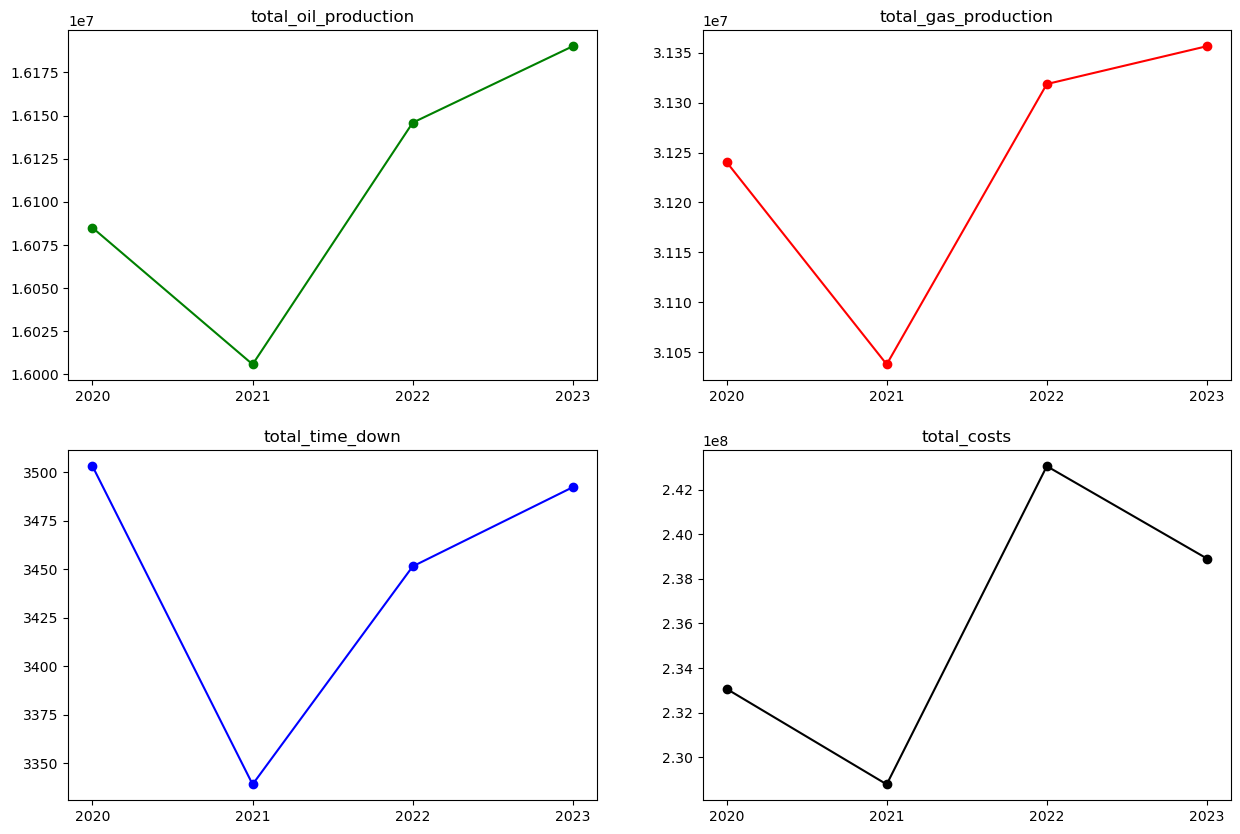

In [5]:
fig, axes = plt.subplots(2, 2, figsize = (15,10))
axes = axes.flatten()
axes[0].plot(business_baseline['year'], business_baseline['total_oil_production'], color = 'green',marker = 'o')
axes[0].set_title('total_oil_production')
axes[1].plot(business_baseline['year'], business_baseline['total_gas_production'], color = 'red',marker = 'o')
axes[1].set_title('total_gas_production')
axes[2].plot(business_baseline['year'], business_baseline['total_time_down'], color = 'blue',marker = 'o')
axes[2].set_title('total_time_down')
axes[3].plot(business_baseline['year'], business_baseline['total_costs'], color = 'black',marker = 'o')
axes[3].set_title('total_costs')

### Key Insights

- From 2021 to 2022, oil production increased by **0.88%** and gas production by **0.90%**, while recorded downtime rose **3.36%** and operating expenditure rose **6.23%**. Downtime and spend therefore grew faster than output in this comparison; this is a signal to investigate, not proof of a specific cause.
- **2023 recorded the highest production** in the four-year view: 16.19 million barrels of oil and 31.36 million mcf of gas. Compared with 2022, operating expenditure fell **1.70%**, while downtime edged up **1.18%**. Tracking whether this pattern persists would help assess operating performance over time.

## 2. Opportunity Cost: Estimated Production Impact of Downtime

This is an operational proxy, not a dollar-valued opportunity cost. It estimates production exposure from each well’s average oil output on positive-production days and recorded downtime hours. The notebook does not contain oil prices or a validated counterfactual, so this should not be interpreted as actual lost production or revenue.

In [6]:
sql_opportunity_cost = '''
WITH avg_operating_rate AS (
    SELECT well_id,
           year(date(production_date)) AS year,
           AVG(NULLIF(oil_production_bbl, 0)) AS avg_daily_oil_bbl
    FROM daily_production
    WHERE year(date(production_date)) IN (2021, 2022)
    GROUP BY well_id, year(date(production_date))
),
downtime_summary AS (
    SELECT well_id,
           year(date(start_datetime)) AS year,
           SUM(downtime_hours) AS downtime_hours
    FROM downtime
    WHERE year(date(start_datetime)) IN (2021, 2022)
    GROUP BY well_id, year(date(start_datetime))
)
SELECT w.well_name,
       f.field_name,
       d.year,
       ROUND(d.downtime_hours, 2) AS downtime_hours,
       ROUND((a.avg_daily_oil_bbl / 24) * d.downtime_hours, 2) AS estimated_lost_oil_bbl
FROM downtime_summary d
JOIN avg_operating_rate a ON d.well_id = a.well_id AND d.year = a.year
JOIN wells w ON d.well_id = w.well_id
JOIN fields f ON w.field_id = f.field_id
ORDER BY estimated_lost_oil_bbl DESC
'''
df_opportunity_cost = sql_to_df(sql_opportunity_cost)
df_opportunity_cost

,well_name,field_name,year,downtime_hours,estimated_lost_oil_bbl
0,APE-013,Apex Deep,2022,81.6,2780.32
1,TIT-002,Titan Basin,2022,63.4,2775.82
2,APE-007,Apex Deep,2022,79.4,2521.36
3,CRE-011,Crestwood Shales,2022,96.8,2454.03
4,APE-011,Apex Deep,2021,70.7,2361.52
...,...,...,...,...,...
145,APE-006,Apex Deep,2021,24.9,388.83
146,APE-015,Apex Deep,2022,13.3,383.90
147,MID-006,Midcon Valley,2022,20.2,372.83
148,CRE-010,Crestwood Shales,2022,19.3,336.74


### Key Insights

- The highest estimated production-exposure records are **APE-013 (2,780.32 bbl; 81.6 downtime hours)** and **TIT-002 (2,775.82 bbl; 63.4 hours)**. Their similar estimates despite different downtime totals reflect that the calculation also uses each well's average positive-production-day output.
- **CRE-011** had the most downtime among the first four ranked records (96.8 hours), with an estimated 2,454.03 bbl of production exposure. These records provide a practical shortlist for review, but the estimates are not verified lost barrels or revenue; validate downtime intervals and well operating rates before using them for financial decisions.

## 3. Field Performance Comparison (2021 vs. 2022)

Compare annual production and downtime by field, then calculate absolute and percentage changes.

In [7]:
sql1 = '''with production_analysis AS (
            select f.field_name,
             round(sum(p.oil_production_bbl), 2) AS oil_production, round(sum(p.gas_production_mcf)) AS gas_production,
             year(date(p.production_date)) AS year
            from 
            wells w join fields f on w.field_id = f.field_id
            join daily_production p on w.well_id = p.well_id
            where year(date(p.production_date)) in (2021, 2022)
            group by f.field_name, year(date(p.production_date))
            ),
            down_time_anlysis AS(
             select f.field_name,
             round(sum(d.downtime_hours), 2) AS total_downtime,
             year(date(d.start_datetime)) AS year
             from wells w join fields f on w.field_id = f.field_id
             join downtime d on d.well_id = w.well_id
             where year(date(d.start_datetime)) in (2021, 2022)
             group by f.field_name, year(date(d.start_datetime))
            )
            select pa.field_name,  pa.year, pa.oil_production, pa.gas_production, COALESCE(da.total_downtime, 0) AS total_downtime
            from production_analysis pa left join down_time_anlysis da
            on pa.field_name = da.field_name and pa.year = da.year
 '''


In [8]:
def prepare_df(sql, index, columns, values, kpis):
    df = sql_to_df(sql)
    df = df.pivot(
        index=index,
        columns=columns,
        values=values
    ).fillna(0)
    df.columns = [
        f'{col}{year}' for col, year in df.columns
    ]
    for kpi in kpis:
        df[f'{kpi}_diff'] = df[f'{kpi}2022'] - df[f'{kpi}2021']
        base_year = df[f'{kpi}2021'].replace(0, float('nan'))
        df[f'{kpi}_diff%'] = (df[f'{kpi}2022'] - df[f'{kpi}2021']) / base_year * 100
    return df

In [9]:
kpis = ['oil_production', 'gas_production', 'total_downtime']
df = prepare_df(sql1, index='field_name',columns='year',values=kpis, kpis=kpis)
df

,oil_production2021,oil_production2022,gas_production2021,gas_production2022,total_downtime2021,total_downtime2022,oil_production_diff,oil_production_diff%,gas_production_diff,gas_production_diff%,total_downtime_diff,total_downtime_diff%
field_name,,,,,,,,,,,,
Apex Deep,3784480.62,3781281.68,7626512.0,7621927.0,670.9,693.2,-3198.94,-0.084528,-4585.0,-0.060119,22.3,3.323893
Crestwood Shales,3550714.54,3585872.16,6515889.0,6555744.0,652.2,619.0,35157.62,0.990156,39855.0,0.611659,-33.2,-5.090463
Midcon Valley,2913072.96,2887878.71,5545139.0,5519566.0,704.3,734.7,-25194.25,-0.864868,-25573.0,-0.461179,30.4,4.316342
Northridge Bakken,2553688.60,2569111.39,5169665.0,5208571.0,745.4,739.0,15422.79,0.603942,38906.0,0.752583,-6.4,-0.858599
Titan Basin,3203844.65,3321732.81,6180606.0,6412760.0,566.4,665.6,117888.16,3.679584,232154.0,3.756169,99.2,17.514124


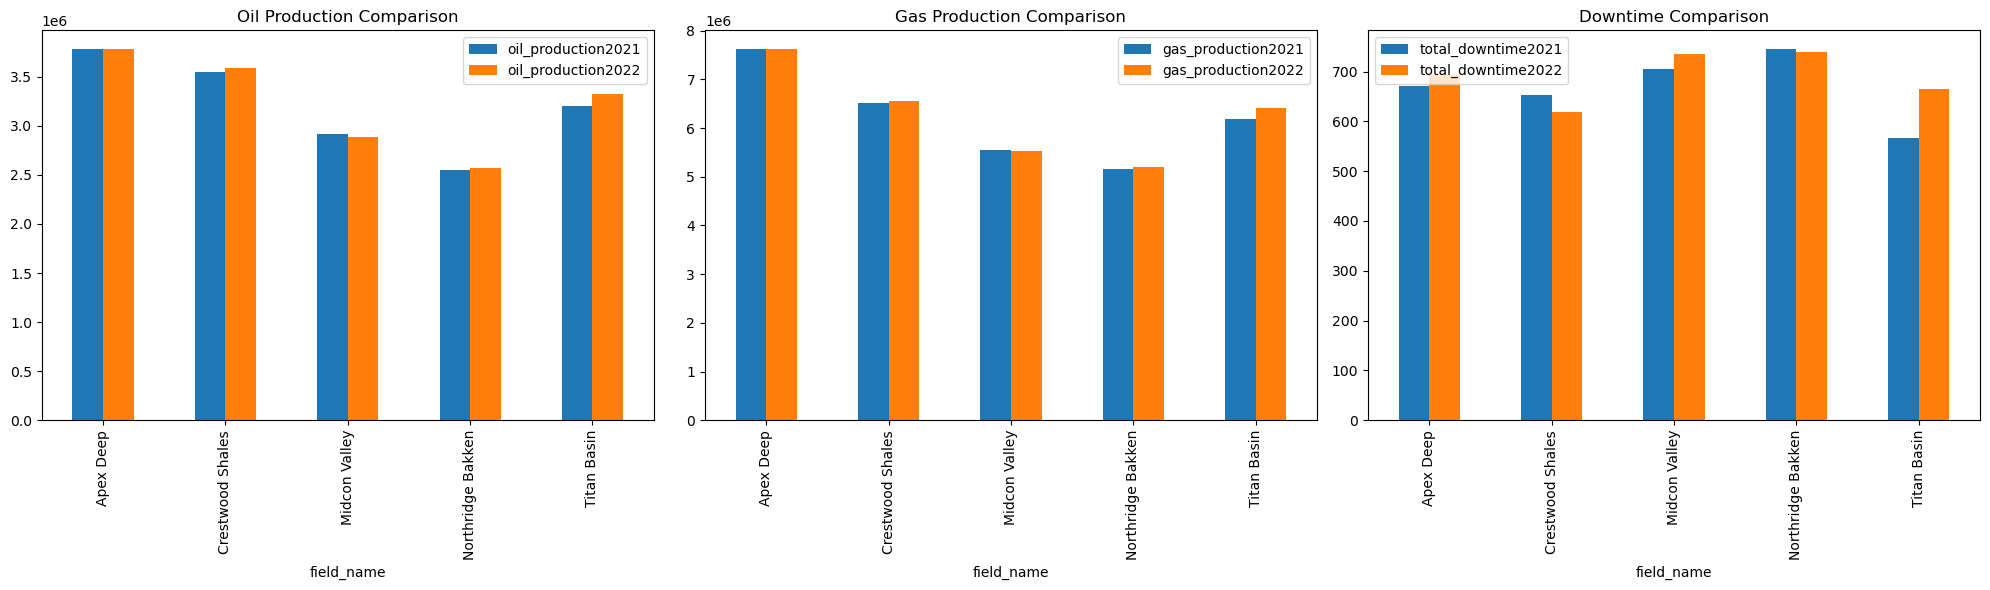

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
df[['oil_production2021', 'oil_production2022']].plot(kind='bar', ax=axes[0], title='Oil Production Comparison')
df[['gas_production2021', 'gas_production2022']].plot(kind='bar', ax=axes[1], title='Gas Production Comparison')
df[['total_downtime2021', 'total_downtime2022']].plot(kind='bar', ax=axes[2], title='Downtime Comparison')
plt.tight_layout()

### Key Insights

- **Titan Basin** had the strongest field-level growth: oil production increased by **3.68%** and gas by **3.76%**, but downtime also increased by **99.2 hours (+17.51%)**. The simultaneous growth and downtime increase make the field a priority for an operational review.
- **Apex Deep** and **Midcon Valley** recorded small declines in both oil and gas production while downtime increased by **3.32%** and **4.32%**, respectively. Their results warrant well-level investigation rather than assuming a field-wide cause.
- **Crestwood Shales** increased production while downtime fell **5.09%**; **Northridge Bakken** also showed modest production growth with slightly lower downtime. Performance differs meaningfully by field, so a single field-level explanation is unlikely to fit all locations.

## 4. Well-Level Performance Comparison (2021 vs. 2022)

Compare production and downtime per well, and flag wells where oil or gas production declined.

In [11]:
sql2 = '''
    with production_performance AS (
    select w.well_name,f.field_name,  year(date(p.production_date)) AS year,
    round(sum(p.oil_production_bbl), 2) AS oil_production,
    round(sum(p.gas_production_mcf)) AS gas_production
    from wells w  join fields f on w.field_id = f.field_id
    join daily_production p on w.well_id = p.well_id
    where year(date(p.production_date)) in (2021, 2022)
    group by  w.well_name,f.field_name, year(date(p.production_date))
    ), 
    down_time_performance AS (
    select w.well_name,f.field_name, year(date(d.start_datetime)) AS year, round(sum(d.downtime_hours), 2) AS total_downtime_hours
    from wells w  join fields f on w.field_id = f.field_id 
    join downtime d on w.well_id = d.well_id
    where year(date(d.start_datetime)) in (2021, 2022)
    group by  w.well_name,f.field_name, year(date(d.start_datetime)) 
    )
    select
      pp.well_name,
      pp.field_name, 
      pp.year,
      pp.oil_production,
      pp.gas_production,
      COALESCE(dp.total_downtime_hours, 0) AS total_downtime
      from production_performance pp left join down_time_performance dp
      on pp.well_name = dp.well_name
      and pp.field_name= dp.field_name
      and pp.year = dp.year
        '''

In [12]:
kpis = ['oil_production', 'gas_production', 'total_downtime']

df2 = prepare_df(sql2, index=['field_name','well_name'],columns='year',values=kpis, kpis=kpis)

In [13]:
df2

oil_production2021  oil_production2022  \
field_name  well_name                                           
Apex Deep   APE-001             295669.95           299634.37   
            APE-002             272206.77           281415.78   
            APE-003             330895.93           351624.59   
            APE-004             273210.23           260041.22   
            APE-005             246538.64           253300.87   
...                                   ...                 ...   
Titan Basin TIT-011             208898.76           217801.31   
            TIT-012             215716.57           241039.09   
            TIT-013             154026.08           160048.67   
            TIT-014             177656.66           169625.89   
            TIT-015             189114.42           207679.73   

                       gas_production2021  gas_production2022  \
field_name  well_name                                           
Apex Deep   APE-001              581385.0            590204.0   
            APE-002              526674.0            542530.0   
            APE-003              709736.0            753475.0   
            APE-004              528683.0            502628.0   
            APE-005              499906.0            514101.0   
...                                   ...                 ...   
Titan Basin TIT-011              344222.0            359414.0   
            TIT-012              439326.0            494521.0   
            TIT-013              268082.0            277503.0   
            TIT-014              335446.0            321773.0   
            TIT-015              412392.0            450546.0   

                       total_downtime2021  total_downtime2022  \
field_name  well_name                                           
Apex Deep   APE-001                  39.7                32.5   
            APE-002                  36.2                26.7   
            APE-003                  28.8                55.8   
            APE-004                  32.2                55.6   
            APE-005                  64.2                23.7   
...                                   ...                 ...   
Titan Basin TIT-011                  29.5                24.6   
            TIT-012                  58.2                73.5   
            TIT-013                  39.7                49.7   
            TIT-014                  50.5                26.7   
            TIT-015                  19.6                33.4   

                       oil_production_diff  oil_production_diff%  \
field_name  well_name                                              
Apex Deep   APE-001                3964.42              1.340826   
            APE-002                9209.01              3.383094   
            APE-003               20728.66              6.264405   
            APE-004              -13169.01             -4.820101   
            APE-005                6762.23              2.742868   
...                                    ...                   ...   
Titan Basin TIT-011                8902.55              4.261658   
            TIT-012               25322.52             11.738792   
            TIT-013                6022.59              3.910111   
            TIT-014               -8030.77             -4.520388   
            TIT-015               18565.31              9.816972   

                       gas_production_diff  gas_production_diff%  \
field_name  well_name                                              
Apex Deep   APE-001                 8819.0              1.516895   
            APE-002                15856.0              3.010591   
            APE-003                43739.0              6.162714   
            APE-004               -26055.0             -4.928284   
            APE-005                14195.0              2.839534   
...                                    ...                   ...   
Titan Basin TIT-011                15192.0              

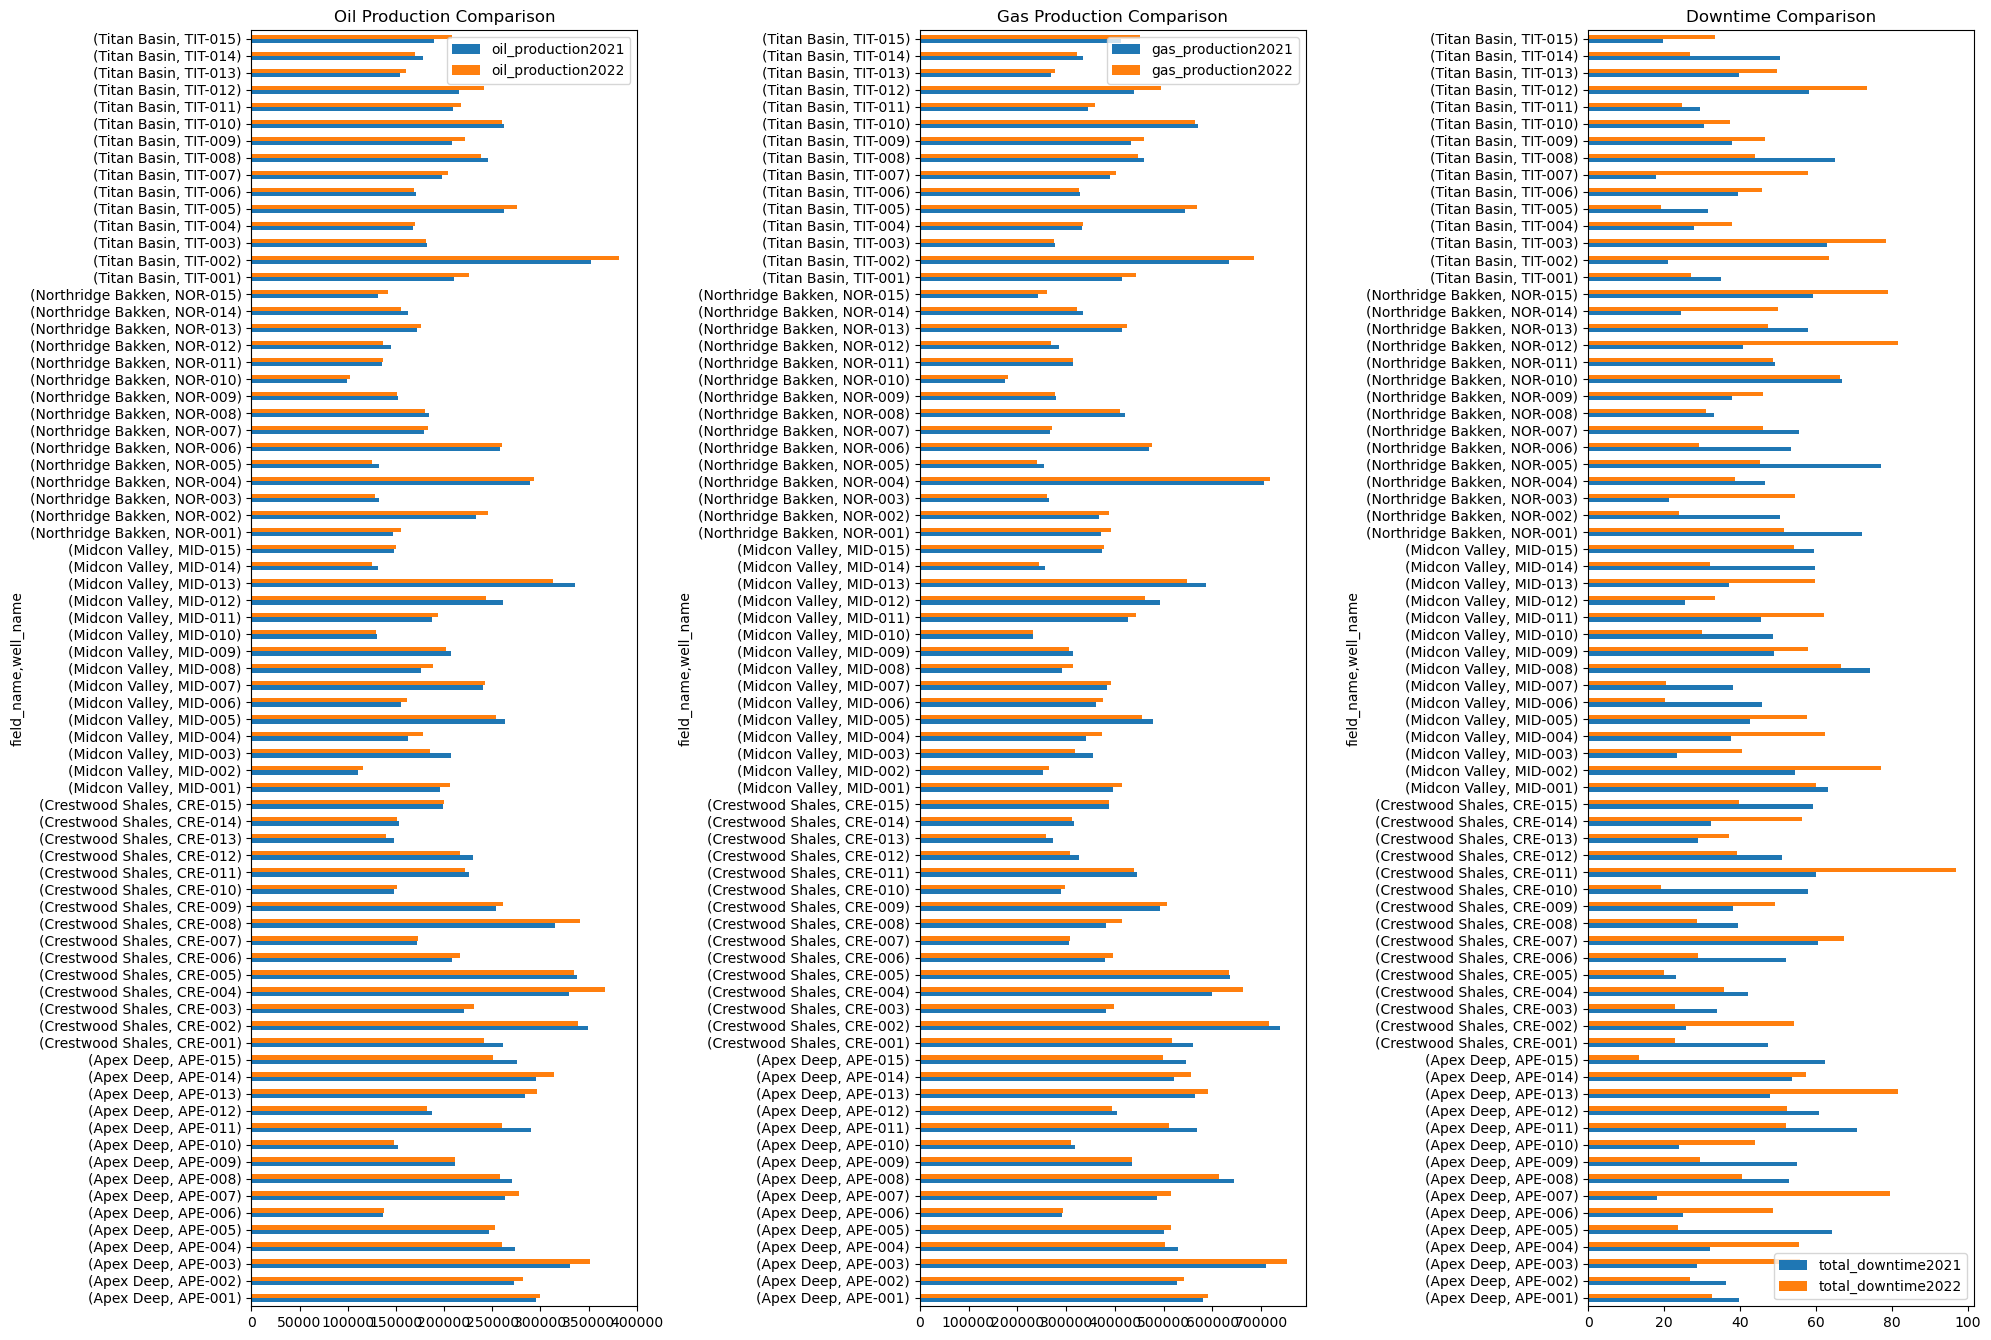

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(20, max(8, len(df2) * 0.18)))
df2[['oil_production2021', 'oil_production2022']].plot(kind='barh', ax=axes[0], title='Oil Production Comparison')
df2[['gas_production2021', 'gas_production2022']].plot(kind='barh', ax=axes[1], title='Gas Production Comparison')
df2[['total_downtime2021', 'total_downtime2022']].plot(kind='barh', ax=axes[2], title='Downtime Comparison')
plt.tight_layout()

In [15]:
df_well_decline = df2[(df2['oil_production_diff'] < 0) |(df2['gas_production_diff'] < 0)].sort_values('oil_production_diff')
df_well_decline

oil_production2021  oil_production2022  \
field_name        well_name                                           
Apex Deep         APE-011             290196.58           260062.55   
                  APE-015             275349.83           250773.50   
Midcon Valley     MID-013             336020.96           313117.06   
                  MID-003             206851.72           185314.67   
Crestwood Shales  CRE-001             261540.49           240926.27   
Midcon Valley     MID-012             260675.28           243857.92   
Crestwood Shales  CRE-012             229986.09           216683.06   
Apex Deep         APE-004             273210.23           260041.22   
                  APE-008             270657.74           257891.97   
Crestwood Shales  CRE-002             349313.55           339249.07   
Midcon Valley     MID-005             263639.43           253653.94   
Northridge Bakken NOR-012             145282.31           137005.89   
Titan Basin       TIT-014             177656.66           169625.89   
Crestwood Shales  CRE-013             147842.16           140021.34   
Northridge Bakken NOR-005             132646.41           124893.48   
                  NOR-014             162293.97           155487.50   
Titan Basin       TIT-008             245166.88           238426.83   
Midcon Valley     MID-014             131707.63           125172.00   
                  MID-009             206683.89           201631.73   
Apex Deep         APE-012             187289.53           182653.89   
                  APE-010             152614.12           148366.61   
Northridge Bakken NOR-008             184146.56           180063.83   
                  NOR-003             132168.12           128587.19   
Crestwood Shales  CRE-011             225611.67           222079.30   
Titan Basin       TIT-010             262633.74           259743.38   
Crestwood Shales  CRE-014             153358.37           150780.46   
                  CRE-005             337411.13           335257.24   
Titan Basin       TIT-006             170358.61           168701.99   
Northridge Bakken NOR-009             152164.79           150870.47   
Titan Basin       TIT-003             182061.14           181393.72   
Midcon Valley     MID-010             130062.56           129583.99   
Apex Deep         APE-009             211108.88           211043.86   

                             gas_production2021  gas_production2022  \
field_name        well_name                                           
Apex Deep         APE-011              568390.0            511367.0   
                  APE-015              545987.0            498764.0   
Midcon Valley     MID-013              587005.0            547040.0   
                  MID-003              355029.0            317964.0   
Crestwood Shales  CRE-001              560424.0            516962.0   
Midcon Valley     MID-012              492158.0            460769.0   
Crestwood Shales  CRE-012              325962.0            306946.0   
Apex Deep         APE-004              528683.0            502628.0   
                  APE-008              644308.0            613129.0   
Crestwood Shales  CRE-002              738441.0            716768.0   
Midcon Valley     MID-005              477383.0            456576.0   
Northridge Bakken NOR-012              285858.0            268358.0   
Titan Basin       TIT-014              335446.0            321773.0   
Crestwood Shales  CRE-013              272507.0            258680.0   
Northridge Bakken NOR-005              255635.0            240858.0   
                  NOR-014              334146.0            322454.0   
Titan Basin       TIT-008              460220.0            446953.0   
Midcon Valley     MID-014              256914.0            244603.0   
                  MID-009              314461.0            306759.0   
Apex Deep         APE-012              403689.0            394959.0   
                  APE-010              318713.0     

### Key Insights

- The decline filter flags **32 well records** where oil production, gas production, or both were lower in 2022 than in 2021. The largest absolute oil decline in the displayed list was **APE-011**, down **30,134 bbl (-10.38%)**; its recorded downtime also fell by 18.6 hours. Its production decline is therefore not explained by an increase in recorded downtime alone.
- **APE-015** also had lower oil output (**-8.93%**) and gas output (**-8.65%**) while downtime decreased by 49.0 hours. In contrast, **MID-013** and **MID-003** had lower production alongside increased downtime, which makes downtime history a relevant part of their review.
- Compare the flagged wells' production-day counts, operating rates, interventions, and downtime reasons before assigning root causes. The table identifies where to investigate, but does not by itself explain why a well's production changed.

## 5. Monthly Production Comparison (2021 vs. 2022)

Compare monthly production and recorded downtime to identify months with year-over-year declines.

In [16]:
sql3 = '''

        with production_performance AS (
        select month(date(p.production_date)) AS month,  year(date(p.production_date)) AS year, round(sum(p.oil_production_bbl), 2) AS oil_production, round(sum(p.gas_production_mcf)) AS gas_production
        from wells w  join fields f on w.field_id = f.field_id
        join daily_production p on w.well_id = p.well_id
        where year(date(p.production_date)) in (2021, 2022)
        group by month(date(p.production_date)), year(date(p.production_date))
        ), 
        down_time_performance AS (
        select month(date(d.start_datetime)) AS month, year(date(d.start_datetime)) AS year, round(sum(d.downtime_hours), 2) AS total_downtime_hours
        from wells w  join fields f on w.field_id = f.field_id 
        join downtime d on w.well_id = d.well_id
        where year(date(d.start_datetime)) in (2021, 2022)
        group by  month(date(d.start_datetime)), year(date(d.start_datetime)) 
        )
        select
	  pp.month,
      pp.year,
      pp.oil_production, 
      pp.gas_production, 
      COALESCE(dp.total_downtime_hours, 0) AS total_downtime
      from production_performance pp left join down_time_performance dp
      on pp.month = dp.month
      and pp.year = dp.year
       '''

In [17]:
kpis = ['oil_production', 'gas_production', 'total_downtime']

df3 = prepare_df(sql3, index=['month'],columns='year',values=kpis, kpis=kpis)
df3

,oil_production2021,oil_production2022,gas_production2021,gas_production2022,total_downtime2021,total_downtime2022,oil_production_diff,oil_production_diff%,gas_production_diff,gas_production_diff%,total_downtime_diff,total_downtime_diff%
month,,,,,,,,,,,,
1,1339329.40,1349019.10,2597850.0,2617050.0,308.2,308.2,9689.70,0.723474,19200.0,0.739073,0.0,0.000000
2,1195807.91,1204939.07,2316688.0,2337039.0,225.7,274.1,9131.16,0.763598,20351.0,0.878452,48.4,21.444395
3,1394109.13,1404886.95,2701869.0,2722795.0,296.6,320.7,10777.82,0.773097,20926.0,0.774501,24.1,8.125421
4,1355020.01,1364255.25,2629432.0,2647959.0,287.1,283.8,9235.24,0.681557,18527.0,0.704601,-3.3,-1.149425
5,1417918.46,1429267.18,2750167.0,2774145.0,239.0,249.9,11348.72,0.800379,23978.0,0.871874,10.9,4.560669
6,1327558.18,1344589.56,2572254.0,2607395.0,313.3,291.2,17031.38,1.282910,35141.0,1.366156,-22.1,-7.053942
7,1364308.71,1375437.56,2649663.0,2673325.0,253.5,277.9,11128.85,0.815713,23662.0,0.893019,24.4,9.625247
8,1376727.44,1383847.64,2668303.0,2682212.0,305.4,408.0,7120.20,0.517183,13909.0,0.521268,102.6,33.595285
9,1308104.91,1320281.00,2533644.0,2556607.0,273.1,251.4,12176.09,0.930819,22963.0,0.906323,-21.7,-7.945807


<Axes: title={'center': 'downtime_comparison'}, ylabel='month'>

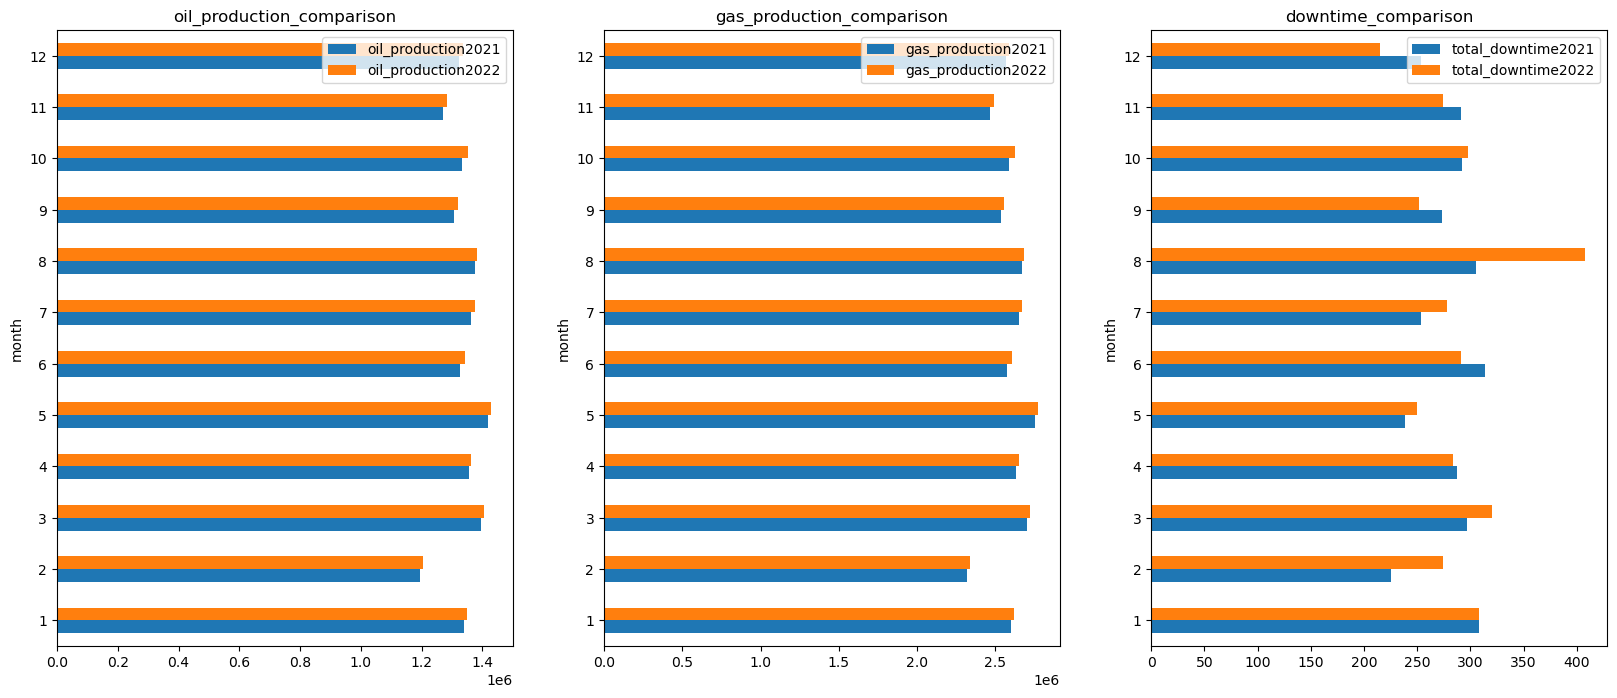

In [18]:
fig, axes = plt.subplots(1,3, figsize = (20,8))
df3[['oil_production2021','oil_production2022']].plot(kind = 'barh' , ax = axes[0], title = 'oil_production_comparison')
df3[['gas_production2021','gas_production2022']].plot(kind = 'barh' , ax = axes[1], title = 'gas_production_comparison')
df3[['total_downtime2021','total_downtime2022']].plot(kind = 'barh' , ax = axes[2], title = 'downtime_comparison')

In [19]:
df_month_decline = df3[(df3['oil_production_diff'] < 0) |(df3['gas_production_diff'] < 0)].sort_values('oil_production_diff')
df_month_decline

,oil_production2021,oil_production2022,gas_production2021,gas_production2022,total_downtime2021,total_downtime2022,oil_production_diff,oil_production_diff%,gas_production_diff,gas_production_diff%,total_downtime_diff,total_downtime_diff%
month,,,,,,,,,,,,


### Key Insights

- Oil and gas production were higher in **all 12 months** of 2022 than in the corresponding months of 2021; the decline-filter output is empty. The largest monthly percentage increases were in **October** (**+1.48%** oil and **+1.44%** gas), although most monthly gains were modest.
- **August downtime increased by 102.6 hours (+33.60%)**, reaching 408.0 hours, even as oil and gas output rose slightly year over year. This is the clearest monthly downtime exception and should be reconciled against the underlying well and downtime-event records. December downtime moved in the opposite direction, falling by 38.7 hours (-15.27%).

## 6. Equipment Maintenance Analysis

Review the mix of planned and unplanned work, changes in maintenance effort and cost, and equipment with the highest maintenance-hour totals.

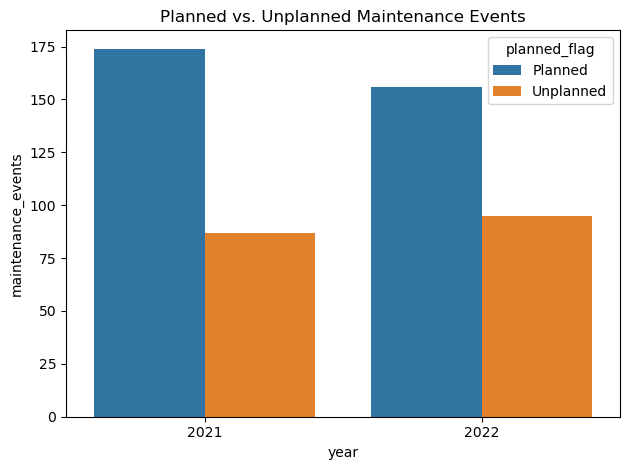

In [20]:
sql4 = '''
SELECT year(date(m.maintenance_date)) AS year,
       m.planned_flag,
       COUNT(*) AS maintenance_events
FROM maintenance m
WHERE year(date(m.maintenance_date)) IN (2021, 2022)
GROUP BY year(date(m.maintenance_date)), m.planned_flag
'''
df4 = sql_to_df(sql4)
sns.barplot(x='year', y='maintenance_events', hue='planned_flag', data=df4).set_title('Planned vs. Unplanned Maintenance Events')
plt.tight_layout()

### Key Insights

- The unplanned share of maintenance events increased from **33.3% in 2021 to 37.8% in 2022**. The chart shows unplanned events increasing while planned events declined, indicating a larger relative share of reactive work.
- This shift is a reason to review work-order categories and failure histories, not enough on its own to conclude that preventive maintenance caused or could prevent the change. The maintenance reason codes and repeat-event patterns would help determine an appropriate response.

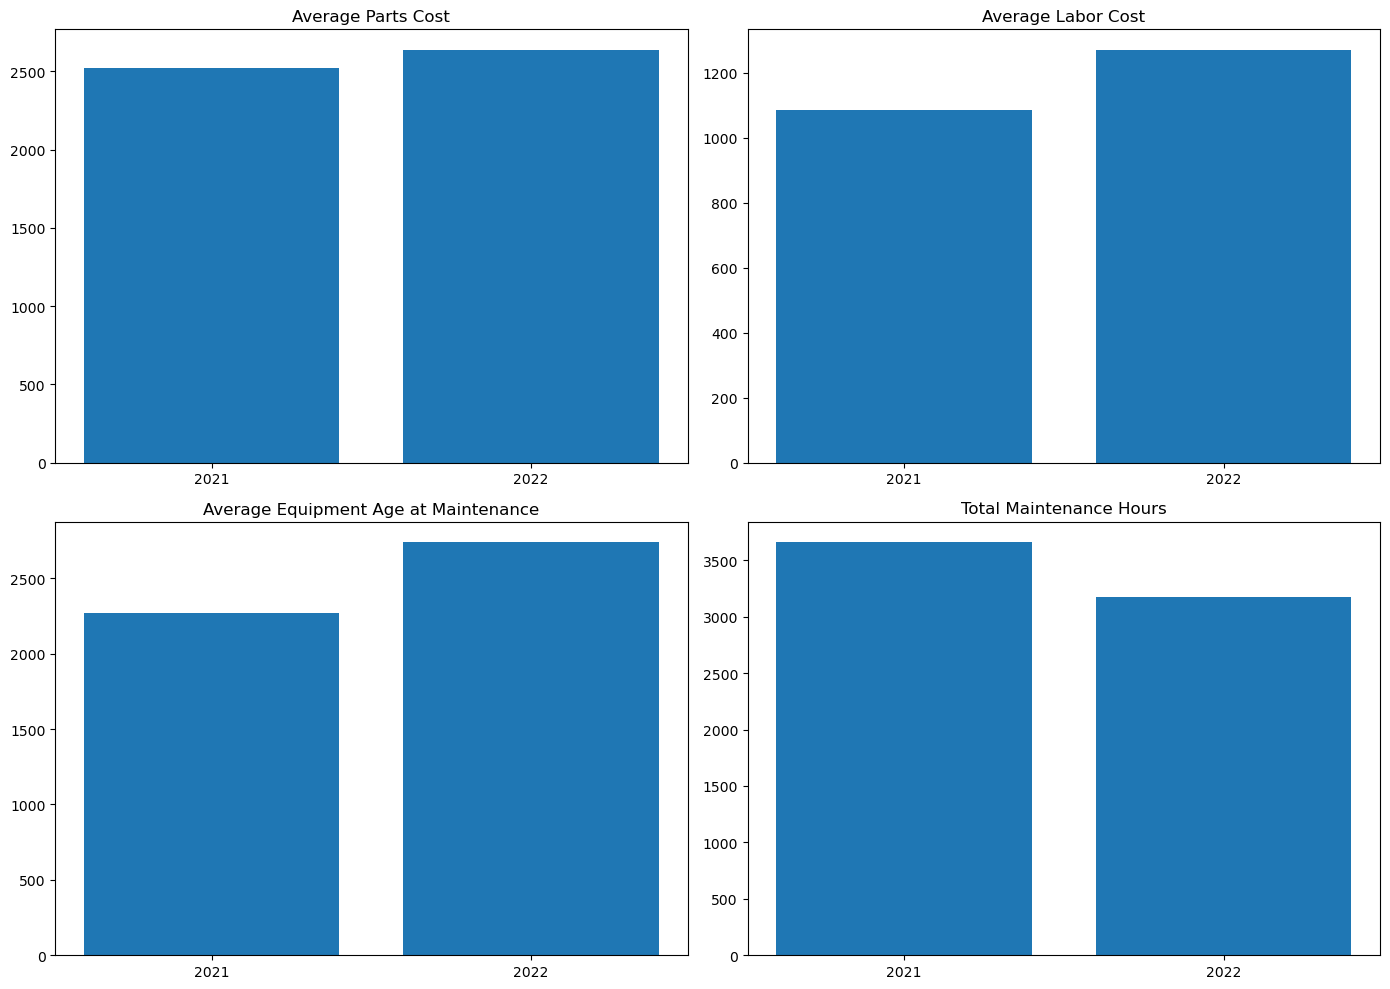

,year,partscost,labor_cost,equipment_age_days,maintenance_hours
0,2021,2519.677050,1084.135441,2271.2567,3657.2
1,2022,2636.408765,1269.458446,2737.0359,3170.5


In [21]:
sql5 = '''
SELECT year(date(m.maintenance_date)) AS year,
       AVG(m.parts_cost) AS partscost,
       AVG(m.labor_cost) AS labor_cost,
       AVG(m.equipment_age_days) AS equipment_age_days,
       SUM(m.maintenance_hours) AS maintenance_hours
FROM maintenance m
WHERE year(date(m.maintenance_date)) IN (2021, 2022)
GROUP BY year(date(m.maintenance_date))
'''
df5 = sql_to_df(sql5)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics = [
    ('partscost', 'Average Parts Cost'),
    ('labor_cost', 'Average Labor Cost'),
    ('equipment_age_days', 'Average Equipment Age at Maintenance'),
    ('maintenance_hours', 'Total Maintenance Hours'),
]
for ax, (metric, title) in zip(axes.flatten(), metrics):
    ax.bar(df5['year'].astype(str), df5[metric])
    ax.set_title(title)
plt.tight_layout()
plt.show()
df5

### Key Insights

- Between 2021 and 2022, average parts cost per recorded maintenance event increased **4.63%** and average labor cost increased **17.09%**. Average equipment age at maintenance also rose **20.51%**, from about 2,271 to 2,737 days.
- Total recorded maintenance hours fell **13.31%** (3,657.2 to 3,170.5 hours) over the same period. Higher average costs alongside fewer aggregate hours deserve follow-up, but these figures alone do not establish total maintenance spend, explain the cost changes, or show that reliability improved.

In [22]:
sql6 = '''select e.equipment_id,
         round(sum(m.maintenance_hours), 2) AS maintenance_hours,
         max(m.equipment_age_days) As equipment_age_days
         from maintenance m left join equipment e
         on m.equipment_id = e.equipment_id
         where year(date(m.maintenance_date)) = 2022
         group by e.equipment_id; '''
df6 = sql_to_df(sql6)
df6 = df6.sort_values('maintenance_hours',ascending = False)
df6['maintenance_hours_participation'] =df6['maintenance_hours'] / df6['maintenance_hours'].sum() *100
df6['cumulative_hours'] = df6['maintenance_hours_participation'].cumsum()
df6

,equipment_id,maintenance_hours,equipment_age_days,maintenance_hours_participation,cumulative_hours
86,EQ-0112,82.7,3604,2.608421,2.608421
17,EQ-0021,82.1,3766,2.589497,5.197918
48,EQ-0060,81.2,2930,2.561110,7.759029
13,EQ-0016,79.2,3598,2.498029,10.257057
15,EQ-0019,78.3,2225,2.469642,12.726699
...,...,...,...,...,...
43,EQ-0054,5.6,2755,0.176628,99.492194
16,EQ-0020,4.6,3609,0.145088,99.637281
73,EQ-0098,4.4,1171,0.138779,99.776061
8,EQ-0010,3.7,1524,0.116701,99.892761


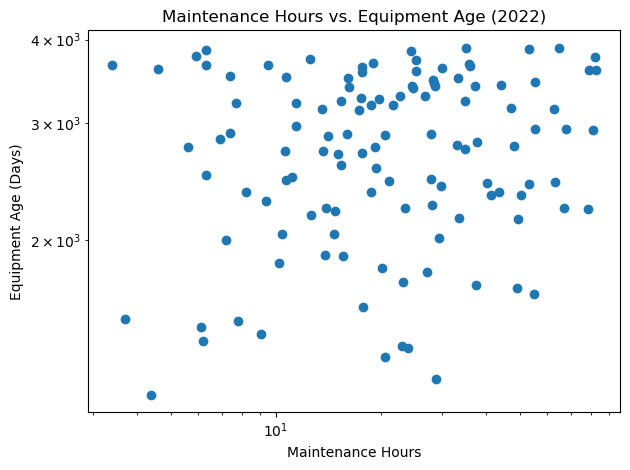

In [23]:
plt.scatter(df6['maintenance_hours'], df6['equipment_age_days'])
plt.xscale('log')
plt.yscale('log')
plt.title('Maintenance Hours vs. Equipment Age (2022)')
plt.xlabel('Maintenance Hours')
plt.ylabel('Equipment Age (Days)')
plt.tight_layout()
plt.show()

### Key Insights

- The 2022 equipment table covers **119 assets**. The highest maintenance-hour totals were for **EQ-0112 (82.7 hours; 2.61% of recorded hours)**, **EQ-0021 (82.1 hours)**, and **EQ-0060 (81.2 hours)**. The ten highest-hour assets together account for about **23.0%** of maintenance hours, so the workload is spread across multiple assets rather than dominated by one item.
- The age-versus-maintenance-hours scatter plot does not show a clear visual monotonic pattern. Equipment age alone should not be used to rank maintenance risk from this chart; repeat work orders, failure types, maintenance costs, and associated downtime would add useful context. No formal correlation test is shown here.

## Findings & Follow-up

Based on the included synthetic dataset, 2022 production was modestly higher than 2021 (oil **+0.88%**, gas **+0.90%**), while recorded downtime increased **3.36%** and operating expenditure increased **6.23%**. Production changes varied by well: **32 of 75 wells** had lower oil output in 2022, with `APE-011` showing the largest absolute decline. The share of unplanned maintenance events also increased from **33.3% to 37.8%**, and the 10 equipment assets with the most maintenance hours accounted for **23.0%** of 2022 maintenance hours.

**Suggested follow-up:** inspect the production and downtime history of the wells with the largest declines, investigate the increased downtime in Titan Basin, and review the unplanned maintenance and high-hour equipment records. These are descriptive signals in synthetic data, not proof of cause. The downtime-based oil estimate is an operational screening proxy, not actual lost production or financial loss.

## Key Findings & Recommendations

### Key Findings

- From 2021 to 2022, oil and gas production grew by less than **1%**, while recorded downtime increased **3.36%** and operating expenditure increased **6.23%**. In 2023, production reached the highest levels in the period and operating expenditure fell **1.70%** from 2022, although downtime rose another **1.18%**.
- Field performance was uneven. Titan Basin delivered the strongest production growth (**+3.68% oil; +3.76% gas**) while downtime increased **99.2 hours (+17.51%)**. Apex Deep and Midcon Valley showed production declines alongside higher downtime.
- The well-level decline filter flags **32 wells** with a year-over-year decrease in oil and/or gas production. APE-011 had the largest absolute oil decline in the displayed list (**-30,134 bbl; -10.38%**) even though its recorded downtime fell.
- The unplanned share of maintenance events rose from **33.3% to 37.8%**. Average parts and labor costs per event increased **4.63%** and **17.09%**, respectively, while total maintenance hours fell **13.31%**.
- Estimated downtime-related production exposure is concentrated in specific well-period records, but the estimate is a screening proxy rather than confirmed lost output or revenue. The equipment chart also provides no clear visual evidence that age alone explains maintenance hours.

### Recommendations

- **Investigate downtime in Titan Basin and August first.** Break the additional **99.2 hours** in Titan Basin and the **102.6-hour** August increase into well, event, and failure-reason categories; reconcile the records before selecting corrective actions.
- **Review the wells with the largest production declines.** Start with APE-011 and APE-015, then MID-013 and MID-003. Compare operating days, production rates, interventions, and downtime reasons to establish whether changes in downtime explain the output changes.
- **Diagnose the rise in unplanned maintenance.** Review work orders by failure mode, equipment, parts, and labor, and identify repeat failures before changing preventive-maintenance schedules or assuming a cause.
- **Prioritize equipment using multiple risk indicators.** Examine high-hour assets such as EQ-0112, EQ-0021, and EQ-0060 alongside repeat work orders, failure severity, cost, and related downtime; do not rank assets by age or maintenance hours alone.
- **Validate before monetizing downtime exposure.** Reconcile downtime intervals with well-level operating rates and an approved oil-price assumption, then label the result as estimated exposure unless a defensible counterfactual confirms actual lost production and revenue.